# 01 · Llevar La Lindosa y Los Micos a resolución horaria

**Proyecto:** Sistema de datos para la predicción hidrológica (CAM, río Las Ceibas).

**Objetivo de este notebook:** convertir las series consolidadas de las estaciones **La Lindosa** y **Los Micos** a **un dato por hora**, para que todos los años sean comparables entre sí.

## ¿Por qué hace falta?

Los archivos consolidados (`data/processed/<estación>/<estación>_consolidado.csv`) mezclan dos resoluciones:

| Periodo | Fuente | Un dato cada… | Qué significa la lluvia de una fila |
|---|---|---|---|
| 2017 – feb 2020 | MAIGRAI (Excel) | 60 min | lluvia caída en **1 hora** |
| feb 2020 – 2025 | MeerKAD (CSV) | ~5 min | lluvia caída en **5 minutos** |

Si un modelo recibe las dos resoluciones mezcladas, aprende patrones falsos (por ejemplo, creería que antes de 2020 llovía 12 veces más por registro). Por eso se lleva todo a la resolución más gruesa que tienen en común: **1 hora**.

## Reglas de agregación

| Variable | Cómo se resume una hora de datos de 5 min | Por qué |
|---|---|---|
| `nivel_m` (nivel del río, m) | **promedio** | el nivel es un estado: la mejor representación de la hora es su valor medio |
| `temperatura_c` (°C) | **promedio** | igual que el nivel |
| `lluvia_mm` (mm) | **suma** | la lluvia es un acumulado: la lluvia de la hora es la suma de las lluvias de cada 5 min |

## Pasos

1. Cargar los consolidados.
2. Redondear las marcas de tiempo de 5 min al múltiplo de 5 min más cercano y resolver duplicados (paso tomado del ítem D del artículo).
3. Agregar a 1 hora con un **mínimo de registros por hora** para que el promedio o la suma sean representativos.
4. Unir los años horarios (MAIGRAI) con los agregados (MeerKAD).
5. Construir la **grilla horaria completa** (una fila por cada hora, aunque no haya dato).
6. Filtro de **sensor pegado** en el nivel (pendiente desde la consolidación).
7. Guardar `data/processed/<estación>/<estación>_horario.csv`, que es la entrada del notebook 02.

## 0. Librerías y parámetros

Todos los parámetros que se pueden discutir están juntos aquí arriba, para cambiarlos fácilmente y volver a ejecutar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Carpeta raíz del repositorio (funciona si el notebook se abre desde /notebooks o desde la raíz)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = RAIZ / "data" / "processed"

ESTACIONES = ["La_Lindosa", "Los_Micos"]

# Nombres cortos y sin símbolos para trabajar más cómodo en Python
RENOMBRAR = {"nivel_(m)": "nivel_m", "temperatura_(°C)": "temperatura_c", "lluvia_(mm)": "lluvia_mm"}
VARIABLES = ["nivel_m", "temperatura_c", "lluvia_mm"]

# Mínimo de registros de 5 min (de 12 posibles) para aceptar el valor de una hora
MIN_REG_PROMEDIO = 6   # nivel y temperatura: con la mitad de la hora el promedio ya es representativo
MIN_REG_LLUVIA = 10    # lluvia: si faltan muchos registros, la suma subestima la lluvia real

# Sensor pegado: más de este número de horas seguidas con el mismo valor exacto de nivel
UMBRAL_PEGADO_H = 24

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Cargar los consolidados

Se leen solo las columnas que existen en estas dos estaciones: nivel, temperatura y lluvia, más `fuente` (MAIGRAI o MeerKAD) e `intervalo_min` (60 o 5).

In [2]:
consolidados = {}
for est in ESTACIONES:
    df = pd.read_csv(PROCESSED / est / f"{est}_consolidado.csv", parse_dates=["fecha_hora"])
    consolidados[est] = df.rename(columns=RENOMBRAR)
    print(f"{est}: {len(df):,} filas, de {df.fecha_hora.min()} a {df.fecha_hora.max()}")

consolidados["La_Lindosa"].head()

La_Lindosa: 607,587 filas, de 2017-06-23 10:00:00 a 2025-12-31 23:59:00


Los_Micos: 609,480 filas, de 2017-06-23 17:00:00 a 2025-12-31 20:47:00


,fecha_hora,nivel_m,temperatura_c,lluvia_mm,fuente,intervalo_min
0,2017-06-23 10:00:00,NaN,NaN,0.000,MAIGRAI,60
1,2017-06-23 11:00:00,0.660,NaN,0.000,MAIGRAI,60
2,2017-06-23 12:00:00,0.660,NaN,0.000,MAIGRAI,60
3,2017-06-23 13:00:00,0.660,NaN,0.000,MAIGRAI,60
4,2017-06-23 14:00:00,0.660,NaN,0.000,MAIGRAI,60


### Frecuencia de muestreo dominante

El artículo (ítem C) define la frecuencia dominante como la **moda** (valor más repetido) de las diferencias entre marcas de tiempo consecutivas. La calculamos por fuente para confirmar lo que dice el README del consolidado.

In [3]:
filas = []
for est, df in consolidados.items():
    for fuente, sub in df.groupby("fuente"):
        dif_min = sub.fecha_hora.diff().dt.total_seconds().div(60).dropna()
        filas.append({"estación": est, "fuente": fuente, "registros": len(sub),
                      "frecuencia dominante (min)": dif_min.mode().iloc[0],
                      "% de pasos iguales a la moda": 100 * (dif_min == dif_min.mode().iloc[0]).mean()})
pd.DataFrame(filas)

,estación,fuente,registros,frecuencia dominante (min),% de pasos iguales a la moda
0,La_Lindosa,MAIGRAI,21579,60.000,99.898
1,La_Lindosa,MeerKAD,586008,5.000,96.981
2,Los_Micos,MAIGRAI,20707,60.000,99.932
3,Los_Micos,MeerKAD,588773,5.000,97.252


Se confirma: MAIGRAI registra cada **60 min** y MeerKAD cada **5 min**. En MeerKAD no todos los pasos son exactamente de 5 min: el registrador a veces escribe a las 00:02, 00:07, 00:13… Por eso el siguiente paso redondea los tiempos.

## 2. Redondear a múltiplos de 5 min y resolver duplicados (solo MeerKAD)

Tal como propone el artículo (ítem D), los registros con pequeños desfases (por ejemplo 00:26 en vez de 00:25) se llevan al múltiplo de 5 minutos más cercano. Si dos registros caen en la misma ranura de 5 min, se conserva **el primer valor no nulo de cada columna** (la misma regla que usa el artículo para los duplicados).

In [4]:
def redondear_5min(df):
    """Redondea la hora de cada registro de 5 min y fusiona los que quedan en la misma ranura."""
    mk = df[df.fuente == "MeerKAD"].copy()
    mk["fecha_hora"] = mk["fecha_hora"].dt.round("5min")
    antes = len(mk)
    mk = mk.groupby("fecha_hora", as_index=False)[VARIABLES].first()
    return mk, antes - len(mk)

cinco_min = {}
for est, df in consolidados.items():
    cinco_min[est], fusionados = redondear_5min(df)
    print(f"{est}: {fusionados} registros fusionados por caer en la misma ranura de 5 min")

La_Lindosa: 90 registros fusionados por caer en la misma ranura de 5 min
Los_Micos: 37 registros fusionados por caer en la misma ranura de 5 min


## 3. Agregar los datos de 5 min a 1 hora

Cada registro se asigna a la hora en que ocurrió (`fecha_hora` truncada a la hora: de 14:00 a 14:55 → **14:00**). Así la etiqueta horaria significa "la hora que empieza a las HH:00", que es también como vienen rotulados los datos MAIGRAI.

Para cada hora se calculan el promedio (nivel, temperatura) o la suma (lluvia) **y cuántos registros de 5 min había**. Si hay menos del mínimo definido arriba, la hora queda vacía: un promedio hecho con 1 o 2 lecturas, o una suma de lluvia con la mitad de la hora perdida, sería engañoso.

In [5]:
def agregar_horario(mk):
    g = mk.assign(hora=mk.fecha_hora.dt.floor("h")).groupby("hora")
    h = pd.DataFrame({
        "nivel_m": g.nivel_m.mean(),
        "temperatura_c": g.temperatura_c.mean(),
        "lluvia_mm": g.lluvia_mm.sum(min_count=1),
        "n_nivel": g.nivel_m.count(),
        "n_temperatura": g.temperatura_c.count(),
        "n_lluvia": g.lluvia_mm.count(),
    })
    descartes = {
        "nivel_m": h.n_nivel.between(1, MIN_REG_PROMEDIO - 1),
        "temperatura_c": h.n_temperatura.between(1, MIN_REG_PROMEDIO - 1),
        "lluvia_mm": h.n_lluvia.between(1, MIN_REG_LLUVIA - 1),
    }
    for var, mascara in descartes.items():
        h.loc[mascara, var] = np.nan
    h["nivel_m"] = h["nivel_m"].round(3)
    h["temperatura_c"] = h["temperatura_c"].round(2)
    h["lluvia_mm"] = h["lluvia_mm"].round(1)
    return h, {v: int(m.sum()) for v, m in descartes.items()}

horario_mk = {}
for est in ESTACIONES:
    horario_mk[est], descartes = agregar_horario(cinco_min[est])
    # Un registro de las 23:59 del último día se redondea a las 00:00 del día siguiente;
    # se descartan las horas posteriores al último registro original.
    ultima_hora = consolidados[est].fecha_hora.max().floor("h")
    horario_mk[est] = horario_mk[est].loc[:ultima_hora]
    print(f"{est}: {len(horario_mk[est]):,} horas MeerKAD; horas descartadas por pocos registros: {descartes}")

La_Lindosa: 49,309 horas MeerKAD; horas descartadas por pocos registros: {'nivel_m': 200, 'temperatura_c': 45, 'lluvia_mm': 200}


Los_Micos: 49,520 horas MeerKAD; horas descartadas por pocos registros: {'nivel_m': 503, 'temperatura_c': 111, 'lluvia_mm': 213}


¿Cuántos registros de 5 min suele tener cada hora? Si la gran mayoría tiene 11-12, el umbral de 6 (promedios) y 10 (lluvia) casi no descarta datos.

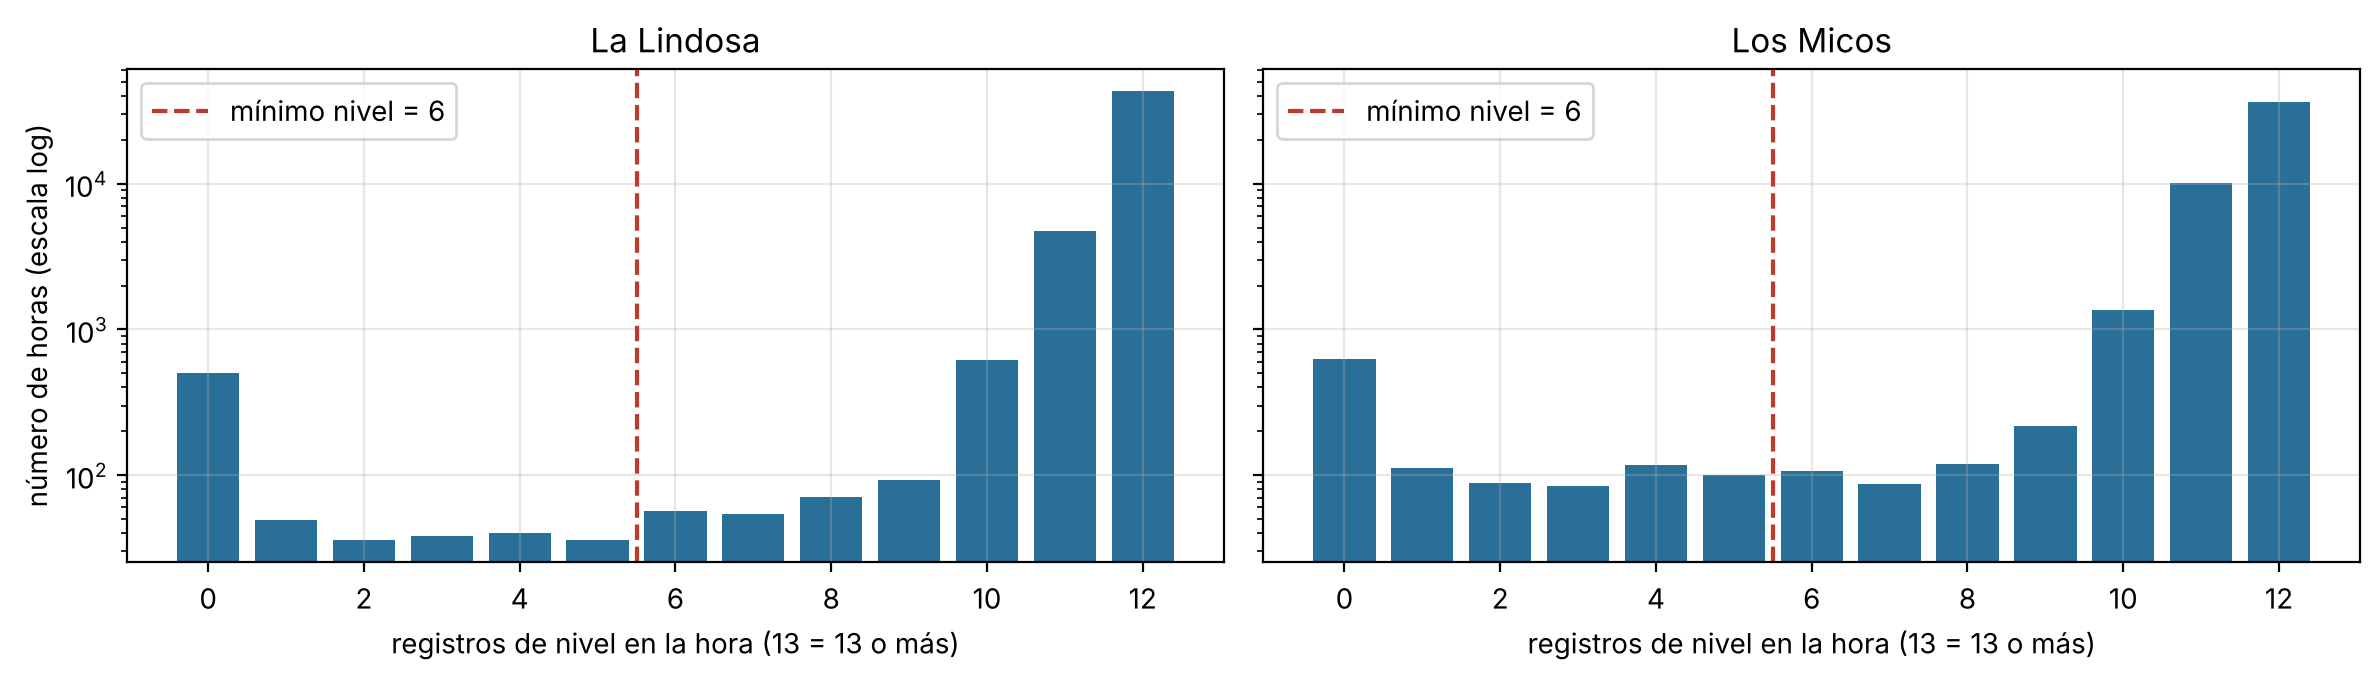

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, est in zip(axes, ESTACIONES):
    conteo = horario_mk[est].n_nivel.clip(upper=13).value_counts().sort_index()
    ax.bar(conteo.index, conteo.values, color="#2a6f97")
    ax.axvline(MIN_REG_PROMEDIO - 0.5, color="#c0392b", ls="--", label=f"mínimo nivel = {MIN_REG_PROMEDIO}")
    ax.set_title(est.replace("_", " "))
    ax.set_xlabel("registros de nivel en la hora (13 = 13 o más)")
    ax.set_yscale("log")
    ax.legend()
axes[0].set_ylabel("número de horas (escala log)")
plt.tight_layout()
plt.show()

## 4. Unir MAIGRAI (ya horario) con MeerKAD (agregado)

Los datos MAIGRAI ya vienen a la hora en punto, así que solo se toman tal cual. Si alguna hora tuviera dato de ambas fuentes (pasa en La Lindosa el 26 de febrero de 2020 a las 14:00, cuando se cambió de sistema), se prefiere MeerKAD y MAIGRAI solo rellena lo que MeerKAD no tenga.

In [7]:
def unir_fuentes(df_cons, h_mk):
    ma = (df_cons[df_cons.fuente == "MAIGRAI"].set_index("fecha_hora")[VARIABLES]
          .assign(fuente="MAIGRAI"))
    ma.index = ma.index.floor("h")
    mk = h_mk[VARIABLES].assign(fuente="MeerKAD")
    solapadas = mk.index.intersection(ma.index)
    unido = mk.combine_first(ma)  # MeerKAD primero; MAIGRAI rellena huecos
    unido.loc[solapadas, "fuente"] = "MeerKAD+MAIGRAI"
    return unido.sort_index(), solapadas

horario = {}
for est in ESTACIONES:
    horario[est], solapadas = unir_fuentes(consolidados[est], horario_mk[est])
    print(f"{est}: {len(horario[est]):,} horas con algún registro; horas con ambas fuentes: {list(solapadas)}")

La_Lindosa: 70,887 horas con algún registro; horas con ambas fuentes: [Timestamp('2020-02-26 14:00:00')]
Los_Micos: 70,227 horas con algún registro; horas con ambas fuentes: []


## 5. Grilla horaria completa

Un modelo de series de tiempo necesita que **cada hora exista como fila**, aunque esté vacía. Así los huecos se ven explícitamente (como celdas vacías) y no "desaparecen". Se crea una fila por cada hora entre el primer y el último registro de cada estación. Las horas sin ningún registro quedan con `fuente = sin_registro`.

In [8]:
for est in ESTACIONES:
    h = horario[est]
    grilla = pd.date_range(h.index.min(), h.index.max(), freq="h", name="fecha_hora")
    faltan = len(grilla) - len(h)
    h = h.reindex(grilla)
    h["fuente"] = h["fuente"].fillna("sin_registro")
    horario[est] = h
    print(f"{est}: grilla de {len(grilla):,} horas ({grilla.min()} a {grilla.max()}); "
          f"{faltan:,} horas no tenían ningún registro")

La_Lindosa: grilla de 74,726 horas (2017-06-23 10:00:00 a 2025-12-31 23:00:00); 3,839 horas no tenían ningún registro
Los_Micos: grilla de 74,716 horas (2017-06-23 17:00:00 a 2025-12-31 20:00:00); 4,489 horas no tenían ningún registro


### Comprobación visual: 5 min frente a horario

Una semana con crecida en 2021. La línea horaria debe seguir la forma de la serie de 5 min, solo que más suave (el promedio quita el ruido de alta frecuencia), y las barras de lluvia horaria son la suma de las de 5 min.

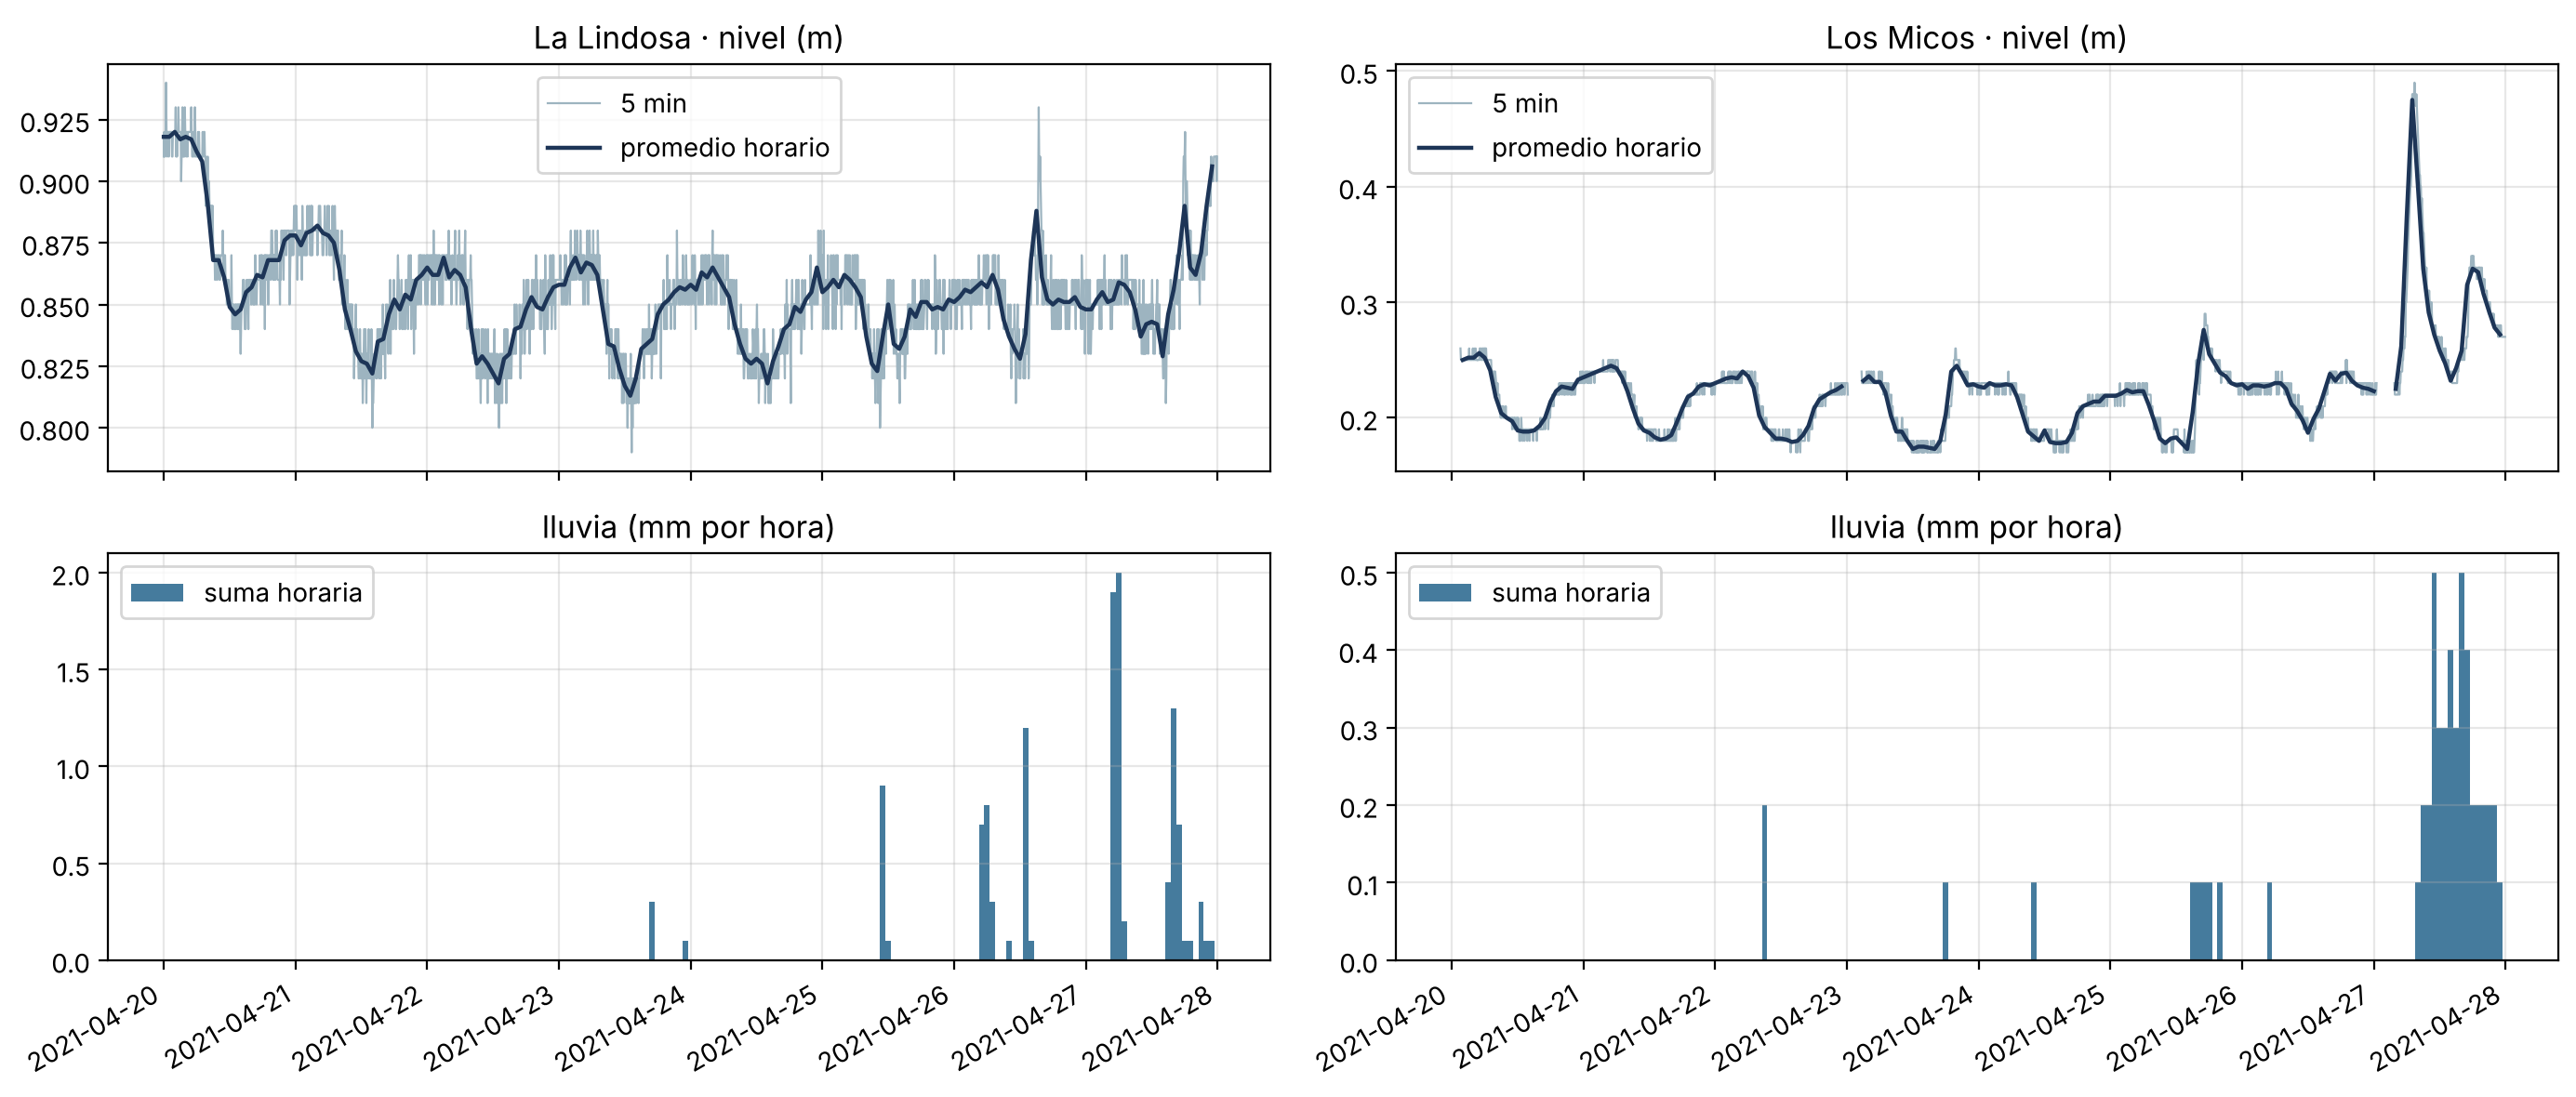

In [9]:
inicio, fin = "2021-04-20", "2021-04-27"
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True)
for j, est in enumerate(ESTACIONES):
    c5 = cinco_min[est].set_index("fecha_hora").loc[inicio:fin]
    h1 = horario[est].loc[inicio:fin]
    axes[0, j].plot(c5.index, c5.nivel_m, color="#9db4c0", lw=0.8, label="5 min")
    axes[0, j].plot(h1.index, h1.nivel_m, color="#1d3557", lw=1.6, label="promedio horario")
    axes[0, j].set_title(f"{est.replace('_', ' ')} · nivel (m)")
    axes[0, j].legend()
    axes[1, j].bar(h1.index, h1.lluvia_mm, width=1 / 24, color="#457b9d", label="suma horaria")
    axes[1, j].set_title("lluvia (mm por hora)")
    axes[1, j].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Comprobación numérica: la lluvia total de cada año debe ser la misma antes y después de agregar (salvo las pocas horas descartadas por tener menos de 10 registros).

In [10]:
filas = []
for est in ESTACIONES:
    c5 = cinco_min[est]
    tot5 = c5.groupby(c5.fecha_hora.dt.year).lluvia_mm.sum()
    hh = horario[est]
    mk = hh[hh.fuente.str.contains("MeerKAD")]
    toth = mk.groupby(mk.index.year).lluvia_mm.sum()
    filas.append(pd.DataFrame({"estación": est, "lluvia 5 min (mm)": tot5, "lluvia horaria (mm)": toth}).dropna())
comparacion = pd.concat(filas)
comparacion.index.name = "año"
comparacion["diferencia (%)"] = 100 * (comparacion["lluvia horaria (mm)"] / comparacion["lluvia 5 min (mm)"] - 1)
comparacion

,estación,lluvia 5 min (mm),lluvia horaria (mm),diferencia (%)
año,,,,
2020,La_Lindosa,420.700,417.400,-0.784
2021,La_Lindosa,"1,429.100","1,413.900",-1.064
2022,La_Lindosa,"1,049.000","1,045.800",-0.305
2023,La_Lindosa,"1,167.600","1,166.300",-0.111
2024,La_Lindosa,"1,142.900","1,142.300",-0.052
2025,La_Lindosa,"1,134.800","1,132.400",-0.211
2020,Los_Micos,876.700,876.600,-0.011
2021,Los_Micos,666.100,665.700,-0.060
2022,Los_Micos,"1,054.200","1,053.100",-0.104


En casi todos los años la diferencia es menor al 1 %: la agregación conserva la lluvia. La diferencia corresponde a las horas incompletas (menos de 10 registros) que se dejaron vacías para no subestimar la lluvia; la más grande es Los Micos 2025 (unos −4 %). Ojo: Los Micos 2025 tiene muy poca lluvia total (~250 mm frente a ~1.000 mm de otros años), lo que se revisa en el EDA (notebook 04).

## 6. Filtro de "sensor pegado" en el nivel

El PDF de observaciones de la CAM dice que los datos MeerKAD (2020-2025) ya se depuraron quitando secuencias de **más de 20 valores idénticos seguidos** (a 5 min, unos 100 minutos), pero que los datos MAIGRAI (2017-2020) **no tuvieron tratamiento**. Ese filtro quedó pendiente en la consolidación.

A resolución horaria no se puede copiar la regla tal cual (20 valores serían 20 horas). Primero miramos cuánto tiempo seguido se repite exactamente el mismo valor de nivel en cada fuente:

In [11]:
def rachas(serie):
    """Tabla con cada secuencia de valores idénticos consecutivos (ignorando horas vacías):
    su largo, su valor, el valor anterior y el siguiente, y la lluvia caída durante ella."""
    s = serie.dropna()
    grupo = (s != s.shift()).cumsum()
    r = s.groupby(grupo).agg(horas="size", valor="first")
    r["inicio"] = s.index.to_series().groupby(grupo).first().values
    r["fin"] = s.index.to_series().groupby(grupo).last().values
    r["anterior"] = r.valor.shift(1)
    r["siguiente"] = r.valor.shift(-1)
    r["salto_m"] = np.fmax((r.valor - r.anterior).abs(), (r.siguiente - r.valor).abs())
    return r, grupo

filas = []
for est in ESTACIONES:
    h = horario[est]
    for fuente in ["MAIGRAI", "MeerKAD"]:
        # se compara con el nivel redondeado a centímetros, que es la resolución de MAIGRAI
        r, _ = rachas(h.loc[h.fuente == fuente, "nivel_m"].round(2))
        largas = r[r.horas > UMBRAL_PEGADO_H]
        filas.append({"estación": est, "fuente": fuente, "racha máxima (h)": r.horas.max(),
                      f"rachas > {UMBRAL_PEGADO_H} h": len(largas),
                      "de ellas, terminan con salto de 1 cm": int((largas.salto_m <= 0.011).sum())})
pd.DataFrame(filas)

,estación,fuente,racha máxima (h),rachas > 24 h,"de ellas, terminan con salto de 1 cm"
0,La_Lindosa,MAIGRAI,242,50,38
1,La_Lindosa,MeerKAD,19,0,0
2,Los_Micos,MAIGRAI,125,138,130
3,Los_Micos,MeerKAD,24,0,0


**Lectura:**

- Con MeerKAD, el nivel horario (redondeado al centímetro) **nunca** se repite más de un día seguido.
- Con MAIGRAI hay muchas rachas de más de 24 h (hasta 10 días). Pero **casi todas empiezan y terminan con un cambio de solo 1 cm**. Eso es lo que se espera de un sensor que funciona y registra con resolución de 1 cm durante una **recesión lenta** del río en época seca: el nivel baja menos de 1 cm por día, así que el valor registrado se queda quieto un par de días y luego baja un escalón. No es un sensor bloqueado.

Por eso **no se anulan todas las rachas largas** (eso habría borrado hasta el 8 % de los datos de Los Micos que en realidad son válidos). Se anula una racha de más de 24 h solo si además hay una señal clara de falla:

1. **al empezar o al terminar la racha el nivel salta de golpe** `SALTO_PEGADO_M` metros o más (el sensor "se despega" y aparece de repente en otro valor), o
2. **durante la racha llovió** `LLUVIA_PEGADO_MM` mm o más y el nivel no se movió ni un centímetro.

In [12]:
SALTO_PEGADO_M = 0.05     # salto al inicio/fin de la racha (percentil ~90 de todos los cambios entre rachas)
LLUVIA_PEGADO_MM = 10     # lluvia acumulada durante la racha sin respuesta del nivel

for est in ESTACIONES:
    h = horario[est]
    r, grupo = rachas(h.nivel_m.round(2))
    r["lluvia_mm"] = [h.loc[i:f, "lluvia_mm"].sum() for i, f in zip(r.inicio, r.fin)]
    sospechosas = r[(r.horas > UMBRAL_PEGADO_H) &
                    ((r.salto_m >= SALTO_PEGADO_M) | (r.lluvia_mm >= LLUVIA_PEGADO_MM))]
    pegado = pd.Series(False, index=h.index)
    pegado.loc[grupo.index[grupo.isin(sospechosas.index)]] = True
    print(f"{est}: {(r.horas > UMBRAL_PEGADO_H).sum()} rachas de más de {UMBRAL_PEGADO_H} h; "
          f"{len(sospechosas)} con señal de falla -> {int(pegado.sum()):,} horas anuladas "
          f"({100 * pegado.sum() / h.nivel_m.notna().sum():.1f} % de las horas con nivel)")
    h["nivel_pegado"] = pegado
    h.loc[pegado, "nivel_m"] = np.nan
    horario[est] = h
    display(sospechosas.sort_values("horas", ascending=False)
            [["inicio", "horas", "valor", "anterior", "siguiente", "lluvia_mm"]])

La_Lindosa: 50 rachas de más de 24 h; 9 con señal de falla -> 693 horas anuladas (1.0 % de las horas con nivel)


,inicio,horas,valor,anterior,siguiente,lluvia_mm
nivel_m,,,,,,
47,2017-07-25 14:00:00,242,0.610,0.620,0.810,26.600
15,2017-06-29 13:00:00,124,0.640,0.650,0.830,9.400
79,2017-08-18 14:00:00,92,0.580,0.600,0.600,14.900
38,2017-07-21 17:00:00,65,0.630,0.890,0.640,1.100
49,2017-08-04 17:00:00,56,0.610,0.810,0.600,1.300
23,2017-07-12 12:00:00,30,0.620,0.840,0.630,2.700
6708,2019-12-19 10:00:00,29,0.860,0.870,0.950,0.000
94,2017-09-05 08:00:00,28,0.600,0.590,0.790,0.000
8,2017-06-26 06:00:00,27,0.650,0.660,0.870,3.700


Los_Micos: 138 rachas de más de 24 h; 2 con señal de falla -> 152 horas anuladas (0.2 % de las horas con nivel)


,inicio,horas,valor,anterior,siguiente,lluvia_mm
nivel_m,,,,,,
576,2018-02-13 10:00:00,106,0.450,0.460,0.560,0.200
2241,2019-04-20 15:00:00,46,0.380,0.390,0.620,2.100


Ejemplo de una racha anulada en La Lindosa (julio-agosto de 2017): el nivel se queda en 0,61 m durante 10 días aunque llovió 27 mm, y la racha solo se interrumpe con un salto brusco a 0,81 m. En rojo, el dato original anulado; en azul, lo que queda.

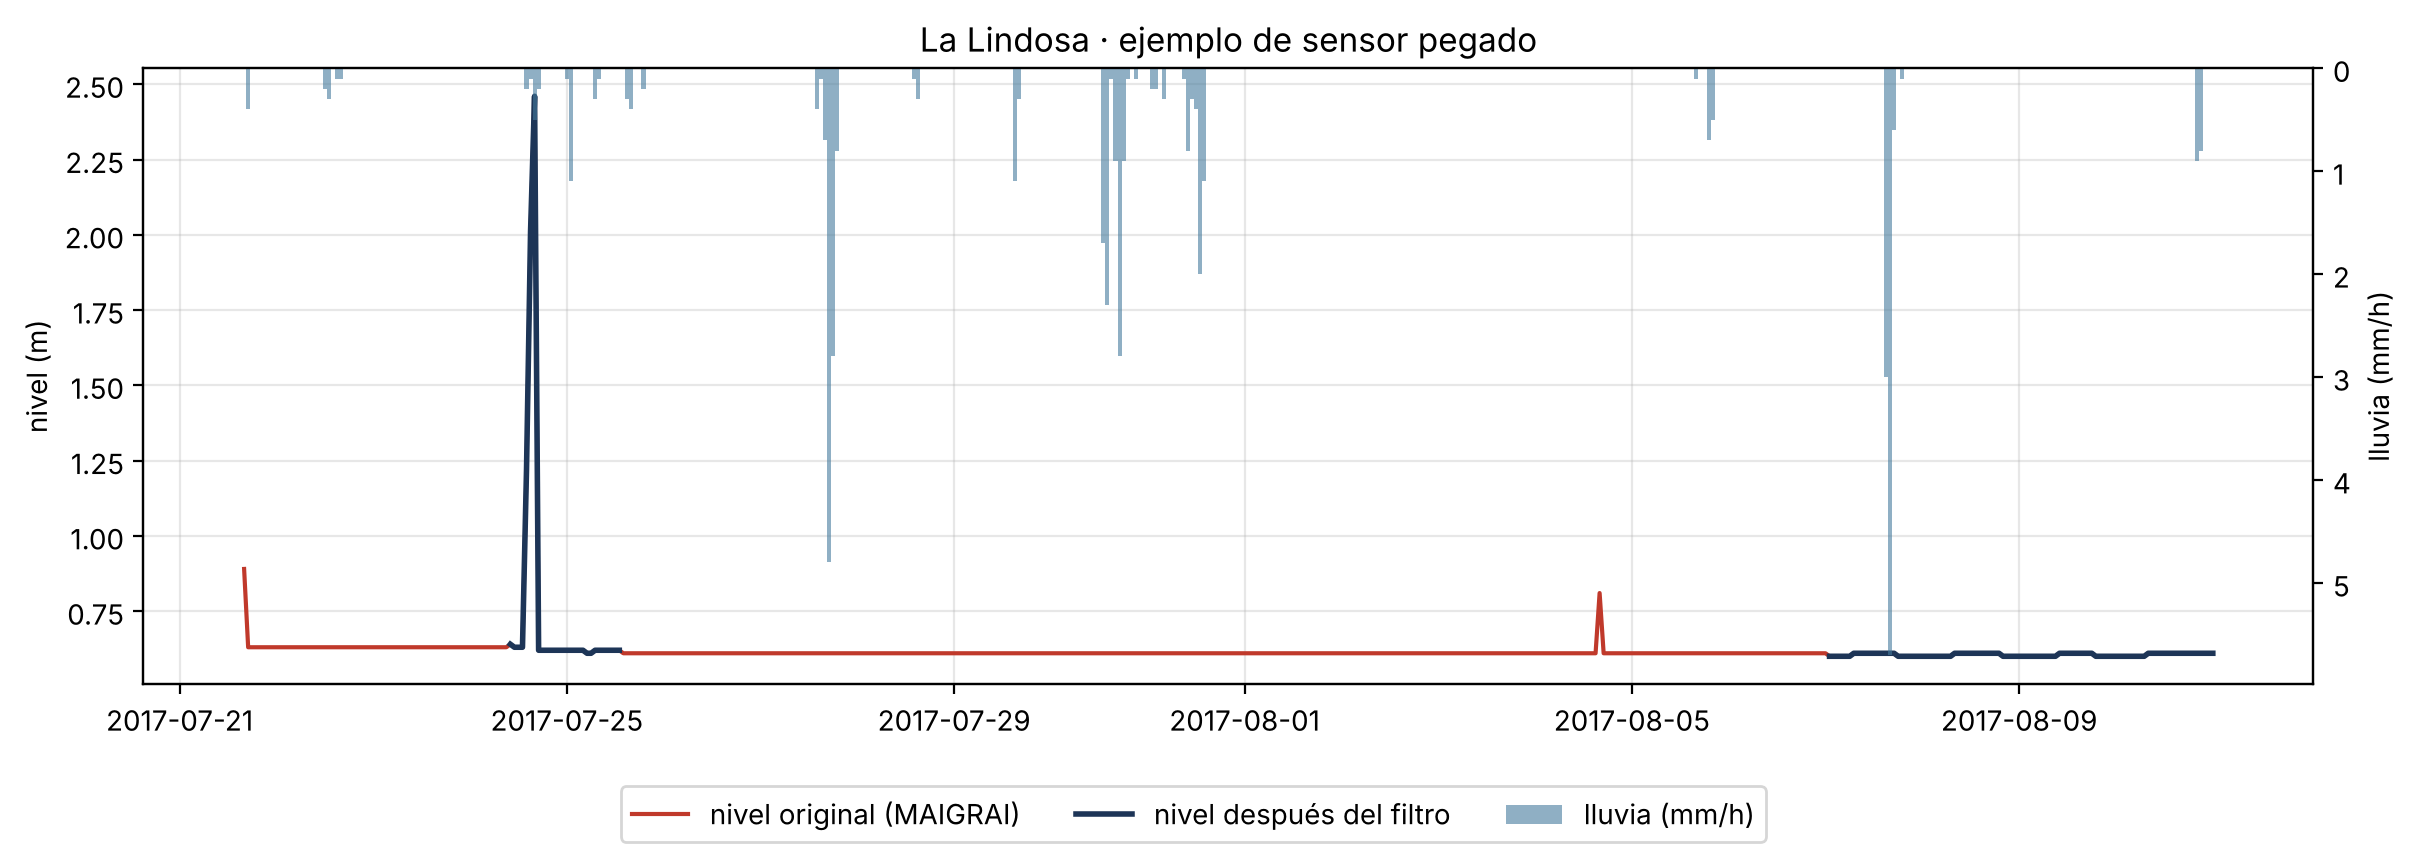

In [13]:
est = "La_Lindosa"
h = horario[est]
idx = h.index[h.nivel_pegado]
mayor_racha = idx[(idx >= "2017-07-25") & (idx < "2017-08-10")]
ventana = h.loc[mayor_racha.min() - pd.Timedelta(days=4): mayor_racha.max() + pd.Timedelta(days=4)]
original = consolidados[est].set_index("fecha_hora").nivel_m.reindex(ventana.index)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ventana.index, original, color="#c0392b", lw=1.5, label="nivel original (MAIGRAI)")
ax.plot(ventana.index, ventana.nivel_m, color="#1d3557", lw=2, label="nivel después del filtro")
ax2 = ax.twinx()
ax2.bar(ventana.index, ventana.lluvia_mm, width=1 / 24, color="#457b9d", alpha=0.6, label="lluvia (mm/h)")
ax2.invert_yaxis()
ax2.grid(False)
ax.set_title(f"{est.replace('_', ' ')} · ejemplo de sensor pegado")
ax.set_ylabel("nivel (m)")
ax2.set_ylabel("lluvia (mm/h)")
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0))
plt.show()

Si el operador confirma otra cosa, basta con cambiar `UMBRAL_PEGADO_H`, `SALTO_PEGADO_M` o `LLUVIA_PEGADO_MM` y volver a ejecutar los notebooks 01 a 04.

**Otros controles revisados y no aplicados:**

- **Rangos físicos** (nivel negativo, temperatura > 60 °C): ya se aplicaron en la consolidación y no se encontraron valores fuera de rango.
- **Temperatura pegada**: no hay ninguna racha de más de 24 h con la misma temperatura, así que no se aplica.
- **Lluvia constante**: hay algunas rachas de 0,1 mm por hora durante 10-18 horas seguidas (en temporada de lluvias de 2020-2022 y 2025). Pueden ser llovizna real o un pluviómetro goteando; no hay forma de distinguirlo con estos datos, así que **no se modifican** y se dejan anotadas para consultar con el operador.

## 7. Resumen y guardado

Cobertura de la serie horaria (porcentaje de horas de la grilla que tienen dato), por año:

In [14]:
for est in ESTACIONES:
    h = horario[est]
    cobertura = h[VARIABLES].notna().groupby(h.index.year).mean().mul(100).round(1)
    cobertura.index.name = "año"
    print(est)
    display(cobertura.T)

La_Lindosa


año,2017,2018,2019,2020,2021,2022,2023,2024,2025
nivel_m,63.900,97.800,91.600,97.200,99.800,94.300,98.500,93.100,87.000
temperatura_c,72.600,97.800,91.900,95.200,99.800,94.300,97.000,64.700,62.000
lluvia_mm,78.400,97.400,91.600,97.000,99.600,94.200,99.800,97.900,86.900


Los_Micos


año,2017,2018,2019,2020,2021,2022,2023,2024,2025
nivel_m,45.700,96.600,94.700,76.500,95.200,97.100,99.400,90.400,93.400
temperatura_c,76.900,97.800,87.000,81.400,99.100,98.600,99.600,90.800,93.800
lluvia_mm,82.600,97.700,95.100,81.300,82.600,98.500,99.500,90.400,93.400


In [15]:
for est in ESTACIONES:
    salida = horario[est].reset_index()
    salida["fecha_hora"] = salida["fecha_hora"].dt.strftime("%Y-%m-%d %H:%M")
    salida = salida[["fecha_hora", "nivel_m", "temperatura_c", "lluvia_mm", "fuente", "nivel_pegado"]]
    ruta = PROCESSED / est / f"{est}_horario.csv"
    salida.to_csv(ruta, index=False)
    print(f"Guardado {ruta.relative_to(RAIZ)} ({len(salida):,} filas)")

Guardado data/processed/La_Lindosa/La_Lindosa_horario.csv (74,726 filas)


Guardado data/processed/Los_Micos/Los_Micos_horario.csv (74,716 filas)


**Resultado:** `data/processed/<estación>/<estación>_horario.csv`, con una fila por hora, las columnas `nivel_m` (promedio), `temperatura_c` (promedio), `lluvia_mm` (suma), `fuente` y `nivel_pegado` (True si el nivel original se anuló por sensor pegado). Todavía tiene huecos: el notebook **02** los caracteriza (ítem C del artículo) y el **03** los rellena (ítems D y E).